# Repaso de las partes A (tipo test), la biblioteca de Lucía

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maximofernandezriera/toqui-devin-sync/blob/main/solucion-partes-a.ipynb)

Lucía es la bibliotecaria del barrio. Cada día presta y recoge libros, ordena signaturas en las estanterías, atiende la pequeña cafetería de la biblioteca y prepara la venta solidaria de ejemplares retirados. Para ahorrar tiempo se ha escrito pequeños programas en Python que le ayudan con estas tareas. En los strings de una estantería, `N` es una novela, `C` un cómic y `.` un hueco libre. Cada ejercicio es independiente: las variables empiezan de nuevo en cada uno y no hace falta haber resuelto los anteriores.

**Borrador.** *Material del docente. Contiene soluciones.*

## Cómo se ha corregido

- Una sola opción correcta por pregunta.
- Cada acierto suma lo que vale en su examen de origen: **1 punto en el WHILE** (P1–P6) y **2 puntos en C-V3 y D-V4** (P7–P11).
- Una respuesta incorrecta no resta.

## Correspondencias cuaderno ↔ exámenes

| Cuaderno | En el examen | Puntos |
|---|---|---:|
| P1 | WHILE A1 | 1 |
| P2 | WHILE A2 | 1 |
| P3 | WHILE A3 | 1 |
| P4 | WHILE A4 | 1 |
| P5 | WHILE A5 | 1 |
| P6 | WHILE A6 | 1 |
| P7 | C-V3 A1 = D-V4 A4 (opciones reordenadas) | 2 |
| P8 | C-V3 A2 | 2 |
| P9 | C-V3 A3 = D-V4 A1 | 2 |
| P10 | C-V3 A4 = D-V4 A3 (opciones reordenadas) | 2 |
| P11 | D-V4 A2 | 2 |

## Caja de herramientas visual

Ejecutad esta celda una sola vez. Prepara la pizarra, las estanterías, el plano del carro y las tablas que usaremos durante el repaso.

In [1]:
#@title Caja de herramientas visual
import doctest
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import HTML, display

FONDO_PIZARRA = "#164638"
TIZA = "#f3f0df"
TIZA_AMARILLA = "#ffe36e"
TIZA_AZUL = "#a9d7ef"

def dibujar_pizarra(titulo, lineas, ancho=10, alto=3.3, guardar=None):
    """Dibuja una idea con texto y flechas sobre fondo de pizarra."""
    fig, ax = plt.subplots(figsize=(ancho, alto), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ax.axis("off")
    ax.text(0.045, 0.91, titulo, color=TIZA_AMARILLA, fontsize=17,
            fontweight="bold", family="DejaVu Sans Mono", va="top")
    cantidad = max(1, len(lineas))
    paso = 0.77 / cantidad
    tamano = 14 if cantidad <= 4 else 12
    for numero, linea in enumerate(lineas):
        if isinstance(linea, tuple):
            texto, color = linea
        else:
            texto, color = linea, TIZA
        ax.text(0.055, 0.78 - numero * paso, texto, color=color,
                fontsize=tamano, family="DejaVu Sans Mono", va="top",
                wrap=True)
    fig.tight_layout(pad=0.5)
    if guardar:
        fig.savefig(guardar, dpi=100, facecolor=FONDO_PIZARRA,
                    bbox_inches="tight")
    display(fig)
    plt.close(fig)

def dibujar_estante(estante, marcar=(), titulo=""):
    """Dibuja las casillas de un estante con los índices debajo."""
    fig, ax = plt.subplots(figsize=(max(5, 1.15 * len(estante)), 2.2), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ax.text(0.05, 0.94, titulo, transform=ax.transAxes, color=TIZA_AMARILLA,
            fontsize=15, fontweight="bold", family="DejaVu Sans Mono", va="top")
    for i, letra in enumerate(estante):
        resaltada = i in marcar
        ax.add_patch(Rectangle((i, 0), 1, 1,
                               facecolor="#205b49",
                               edgecolor=TIZA_AMARILLA if resaltada else TIZA,
                               linewidth=2.5 if resaltada else 1.5))
        ax.text(i + 0.5, 0.56, letra, ha="center", va="center",
                fontsize=20, color=TIZA_AMARILLA if resaltada else TIZA,
                family="DejaVu Sans Mono", fontweight="bold")
        ax.text(i + 0.5, -0.2, str(i), ha="center", va="center",
                fontsize=12, color=TIZA)
    ax.set_xlim(-0.15, max(1, len(estante)) + 0.15)
    ax.set_ylim(-0.55, 1.05)
    ax.axis("off")
    display(fig)
    plt.close(fig)

def dibujar_estantes_doble(antes, despues, titulo):
    """Compara dos estantes en la misma pizarra."""
    fig, ax = plt.subplots(figsize=(10, 3.1), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ax.axis("off")
    ax.text(0.03, 0.94, titulo, transform=ax.transAxes, color=TIZA_AMARILLA,
            fontsize=16, fontweight="bold", family="DejaVu Sans Mono", va="top")
    ancho = max(len(antes), len(despues))
    for fila, (etiqueta, estante) in enumerate((("antes", antes), ("después", despues))):
        y = 0.60 - fila * 0.40
        ax.text(0.04, y + 0.10, etiqueta, transform=ax.transAxes,
                color=TIZA_AZUL, fontsize=13, family="DejaVu Sans Mono")
        for i, letra in enumerate(estante):
            x = 0.21 + 0.73 * i / max(1, ancho)
            w = 0.68 / max(1, ancho)
            ax.add_patch(Rectangle((x, y - 0.05), w, 0.23,
                                   transform=ax.transAxes,
                                   facecolor="#205b49",
                                   edgecolor=TIZA, linewidth=1.2))
            ax.text(x + w / 2, y + 0.065, letra, transform=ax.transAxes,
                    ha="center", va="center", fontsize=15, color=TIZA_AMARILLA,
                    family="DejaVu Sans Mono", fontweight="bold")
    display(fig)
    plt.close(fig)

def tabla_html(filas, columnas):
    """Construye una tabla estática para seguir una vuelta cada vez."""
    estilo = "border:1px solid #b8cbbf;padding:6px 14px;text-align:center;font-size:16px"
    cabecera = "".join(
        f'<th style="{estilo};background:#205b49;color:#fff">{c}</th>'
        for c in columnas
    )
    filas_html = "".join(
        "<tr>" + "".join(
            f'<td style="{estilo};color:#18382e">{fila[c]}</td>'
            for c in columnas
        ) + "</tr>"
        for fila in filas
    )
    return HTML(
        '<table style="border-collapse:collapse">'
        f"<tr>{cabecera}</tr>{filas_html}</table>"
    )

def traza_pasos(filas, columnas, pausa=0):
    """Presenta los datos de cada vuelta en orden."""
    display(tabla_html(filas, columnas))

def dibujar_tabla_pizarra(titulo, columnas, filas, guardar=None):
    """Dibuja una tabla de seguimiento legible en la pizarra."""
    fig, ax = plt.subplots(figsize=(10, max(2.8, 0.48 * (len(filas) + 2))), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ax.axis("off")
    ax.text(0.5, 0.96, titulo, transform=ax.transAxes, ha="center", va="top",
            color=TIZA_AMARILLA, fontsize=15, fontweight="bold",
            family="DejaVu Sans Mono")
    izquierda, derecha = 0.05, 0.95
    arriba, abajo = 0.82, 0.08
    ancho = (derecha - izquierda) / len(columnas)
    alto = (arriba - abajo) / (len(filas) + 1)
    for r in range(len(filas) + 2):
        y = arriba - r * alto
        ax.plot([izquierda, derecha], [y, y], transform=ax.transAxes,
                color=TIZA, linewidth=1)
    for c in range(len(columnas) + 1):
        x = izquierda + c * ancho
        ax.plot([x, x], [abajo, arriba], transform=ax.transAxes,
                color=TIZA, linewidth=1)
    tabla = [columnas] + filas
    for r, fila in enumerate(tabla):
        for c, valor in enumerate(fila):
            x = izquierda + (c + 0.5) * ancho
            y = arriba - (r + 0.5) * alto
            ax.text(x, y, str(valor), transform=ax.transAxes, ha="center",
                    va="center", color=TIZA_AMARILLA if r == 0 else TIZA,
                    fontsize=12, family="DejaVu Sans Mono")
    if guardar:
        fig.savefig(guardar, dpi=100, facecolor=FONDO_PIZARRA,
                    bbox_inches="tight")
    display(fig)
    plt.close(fig)

def dibujar_plano(ruta, titulo, guardar=None):
    """Plano en cuadrícula estilo pizarra con el recorrido del carro."""
    movimientos = {"N": (0, 1), "S": (0, -1), "E": (1, 0), "O": (-1, 0)}
    fig, ax = plt.subplots(figsize=(7.5, 4.8), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ax.set_xlim(-3.6, 3.6)
    ax.set_ylim(-2.9, 3.7)
    ax.set_aspect("equal")
    for gx in range(-3, 4):
        ax.axvline(gx, color="#3f6b5b", linewidth=0.7)
    for gy in range(-2, 4):
        ax.axhline(gy, color="#3f6b5b", linewidth=0.7)
    ax.axhline(0, color=TIZA, linewidth=1.2)
    ax.axvline(0, color=TIZA, linewidth=1.2)
    ax.set_xticks(range(-3, 4))
    ax.set_yticks(range(-2, 4))
    ax.tick_params(colors=TIZA, labelsize=9)
    for spine in ax.spines.values():
        spine.set_color(TIZA)
    ax.set_xlabel("x   (O  \u2190     \u2192  E)", color=TIZA, fontsize=10,
                  family="DejaVu Sans Mono")
    ax.set_ylabel("y   (S  \u2193     \u2191  N)", color=TIZA, fontsize=10,
                  family="DejaVu Sans Mono")
    ax.set_title(titulo, color=TIZA_AMARILLA, fontsize=13, fontweight="bold",
                 family="DejaVu Sans Mono")
    ax.plot(0, 0, marker="s", markersize=12, color=TIZA_AZUL)
    ax.annotate("mostrador\n(0, 0)", (0, 0), (0.3, -1.15), color=TIZA_AZUL,
                fontsize=9, family="DejaVu Sans Mono")
    x, y = 0, 0
    for paso, letra in enumerate(ruta, 1):
        dx, dy = movimientos[letra]
        ax.annotate("", xy=(x + dx, y + dy), xytext=(x, y),
                    arrowprops={"arrowstyle": "-|>", "color": TIZA_AMARILLA,
                                "linewidth": 2})
        ax.text(x + dx / 2 + (0.16 if dx == 0 else 0),
                y + dy / 2 + (0.14 if dy == 0 else 0),
                f"{paso}:{letra}", color=TIZA, fontsize=9,
                family="DejaVu Sans Mono")
        x, y = x + dx, y + dy
    ax.plot(x, y, marker="o", markersize=9, color=TIZA_AMARILLA)
    desfase = 0.3 if movimientos[ruta[-1]][1] >= 0 else -0.9
    ax.annotate(f"acaba en [{x}, {y}]", (x, y), (x + 0.4, y + desfase),
                color=TIZA_AMARILLA, fontsize=10, family="DejaVu Sans Mono")
    if guardar:
        fig.savefig(guardar, dpi=100, facecolor=FONDO_PIZARRA,
                    bbox_inches="tight")
    display(fig)
    plt.close(fig)

print("Caja lista: pizarra, estantes, plano y tablas.")


Caja lista: pizarra, estantes, plano y tablas.


## P1 · Sellar los libros devueltos (WHILE A1 · 1 punto)

### Enunciado exacto

Lucía sella una pila de 5 libros devueltos de uno en uno y para cuando le quedan 2 o menos sin sellar. ¿Qué imprime este código?

```python
libros = 5
while libros > 2:
    libros = libros - 1
print(libros)
```

a) 5    b) 3<br>c) 2    d) El bucle no termina

### Pizarra

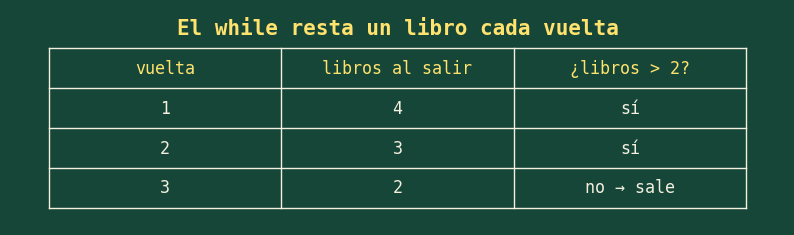

In [2]:
dibujar_tabla_pizarra("El while resta un libro cada vuelta",
    ["vuelta", "libros al salir", "¿libros > 2?"],
    [["1", "4", "sí"],
     ["2", "3", "sí"],
     ["3", "2", "no → sale"]])

In [3]:
libros = 5
while libros > 2:
    libros = libros - 1
print(libros)

2


**Paso a paso.** El `while` comprueba `libros > 2` antes de cada vuelta: `libros` pasa de 5 a 4, a 3 y a 2. Cuando vale 2 la condición ya no se cumple, el bucle no entra y `print` muestra `2`. La respuesta es **c) 2**.

Por qué fallan las demás:

- **a) 5**: ignora las actualizaciones dentro del bucle.
- **b) 3**: detiene el bucle una vuelta antes.
- **d) El bucle no termina**: olvida que `libros` disminuye en cada vuelta.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=libros%20%3D%205%0Awhile%20libros%20%3E%202%3A%0A%20%20%20%20libros%20%3D%20libros%20-%201%0Aprint%28libros%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Respuesta c: sigue el bucle hasta su condición de salida y `libros` termina en 2. | 1 |
| Una respuesta incorrecta no resta. | 0 de resta |

#### Errores frecuentes

- Contar las vueltas que sí entran (3) en lugar de anotar el valor final de `libros`.
- Pensar que el bucle se detiene en cuanto `libros` toca 2 dentro del cuerpo: la condición solo se mira antes de entrar.

## P2 · Préstamos por socio (WHILE A2 · 1 punto)

### Enunciado exacto

Lucía lleva en un diccionario cuántos libros tiene prestados cada socio. Luna se lleva un libro más y Teo se hace socio con 3. ¿Qué imprime este código?

```python
prestamos = {"Luna": 2, "Eva": 1}
prestamos["Luna"] = prestamos["Luna"] + 1
prestamos["Teo"] = 3
print(prestamos["Luna"], len(prestamos))
```

a) 2 2    b) 3 3<br>c) 3 2    d) 2 3

### Pizarra

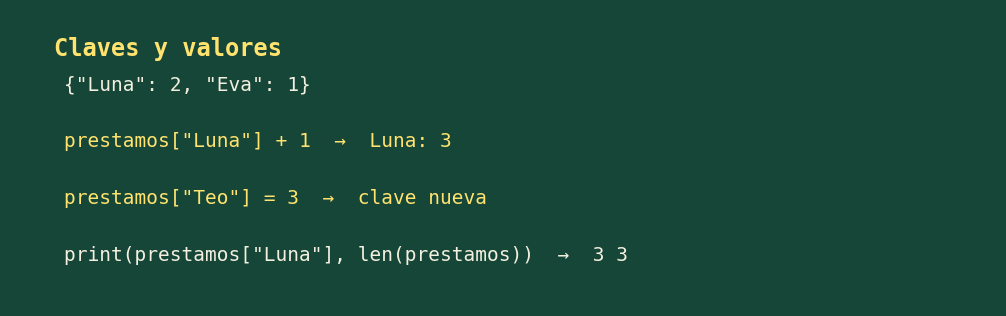

In [4]:
dibujar_pizarra(
    'Claves y valores',
    [('{"Luna": 2, "Eva": 1}', TIZA),
    ('prestamos["Luna"] + 1  →  Luna: 3', TIZA_AMARILLA),
    ('prestamos["Teo"] = 3  →  clave nueva', TIZA_AMARILLA),
    ('print(prestamos["Luna"], len(prestamos))  →  3 3', TIZA)],
    ancho=10, alto=3.1,
)

In [5]:
prestamos = {"Luna": 2, "Eva": 1}
prestamos["Luna"] = prestamos["Luna"] + 1
prestamos["Teo"] = 3
print(prestamos["Luna"], len(prestamos))

3 3


**Paso a paso.** `prestamos["Luna"] + 1` deja a Luna con 3. `prestamos["Teo"] = 3` crea una clave nueva: el diccionario pasa a tener 3 socios. El `print` muestra primero el valor de Luna y después el número de claves: `3 3`. La respuesta es **b) 3 3**.

Por qué fallan las demás:

- **a) 2 2**: ignora la actualización y la nueva clave.
- **c) 3 2**: actualiza Luna pero no cuenta la nueva clave.
- **d) 2 3**: cuenta la nueva clave pero no actualiza Luna.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=prestamos%20%3D%20%7B%22Luna%22%3A%202%2C%20%22Eva%22%3A%201%7D%0Aprestamos%5B%22Luna%22%5D%20%3D%20prestamos%5B%22Luna%22%5D%20%2B%201%0Aprestamos%5B%22Teo%22%5D%20%3D%203%0Aprint%28prestamos%5B%22Luna%22%5D%2C%20len%28prestamos%29%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Respuesta b: actualiza el valor y cuenta la clave nueva. | 1 |
| Una respuesta incorrecta no resta. | 0 de resta |

#### Errores frecuentes

- Leer el `print` al revés: primero va `prestamos["Luna"]` y después `len(prestamos)`.
- Olvidar que asignar a una clave que no existe (`Teo`) la crea, y entonces el `len` sube a 3.
- Prima hermana: la P11 (D-V4 A2) trabaja el mismo mecanismo, pero allí el `print` muestra primero el `len`.

## P3 · Códigos de la estantería de novedades (WHILE A3 · 1 punto)

### Enunciado exacto

Lucía actualiza la lista de códigos de los libros de la estantería de novedades: retira el código 20, que ya está prestado, y añade el 50, que acaba de llegar. ¿Qué imprime este código?

```python
numeros = [10, 20, 30, 40]
numeros.remove(20)
numeros.append(50)
print(numeros[1], len(numeros))
```

a) 30 4    b) 20 4<br>c) 30 3    d) 10 4

### Pizarra

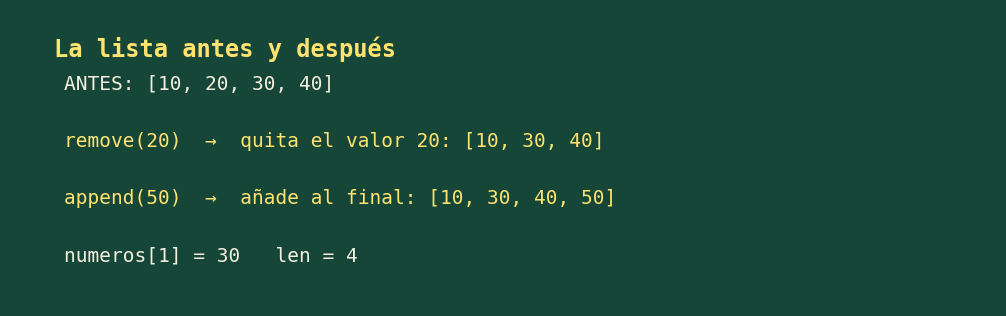

In [6]:
dibujar_pizarra(
    'La lista antes y después',
    [("ANTES: [10, 20, 30, 40]", TIZA),
    ("remove(20)  →  quita el valor 20: [10, 30, 40]", TIZA_AMARILLA),
    ("append(50)  →  añade al final: [10, 30, 40, 50]", TIZA_AMARILLA),
    ("numeros[1] = 30   len = 4", TIZA)],
    ancho=10, alto=3.1,
)

In [7]:
numeros = [10, 20, 30, 40]
numeros.remove(20)
numeros.append(50)
print(numeros[1], len(numeros))

30 4


**Paso a paso.** `remove(20)` quita el valor 20 y la lista queda `[10, 30, 40]`; `append(50)` la deja `[10, 30, 40, 50]`. Entonces `numeros[1]` es `30` y `len(numeros)` es `4`. La respuesta es **a) 30 4**.

Por qué fallan las demás:

- **b) 20 4**: interpreta `remove` como eliminación por índice o cree que el 20 sigue en su sitio.
- **c) 30 3**: cree que `append` sustituye un elemento y la lista sigue teniendo 3.
- **d) 10 4**: error de índice (off-by-one).

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=numeros%20%3D%20%5B10%2C%2020%2C%2030%2C%2040%5D%0Anumeros.remove%2820%29%0Anumeros.append%2850%29%0Aprint%28numeros%5B1%5D%2C%20len%28numeros%29%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Respuesta a: `remove` quita el valor, `append` añade al final y el índice 1 es 30. | 1 |
| Una respuesta incorrecta no resta. | 0 de resta |

#### Errores frecuentes

- Confundir `remove(20)` con quitar la posición 20: borra el valor 20, esté donde esté.
- Creer que `append` sobrescribe el último hueco: añade al final y la lista crece.
- Leer `numeros[1]` como «el primer elemento»: el índice 1 es el segundo.

## P4 · Stock de la cafetería (WHILE A4 · 1 punto)

### Enunciado exacto

En la cafetería de la biblioteca, Lucía controla el stock con un diccionario y consulta las unidades de pan y de agua. ¿Qué imprime este código?

```python
inventario = {"pan": 5, "leche": 2}
print(inventario.get("pan"), inventario.get("agua", 0))
```

a) 5 None    b) 5 agua<br>c) 5 0    d) KeyError

### Pizarra

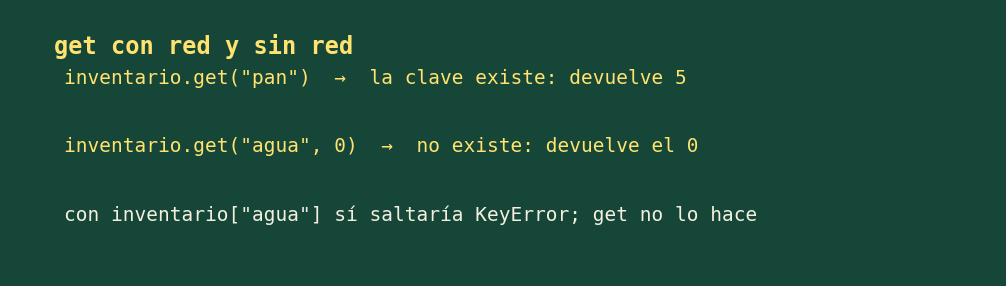

In [8]:
dibujar_pizarra(
    'get con red y sin red',
    [('inventario.get("pan")  →  la clave existe: devuelve 5', TIZA_AMARILLA),
    ('inventario.get("agua", 0)  →  no existe: devuelve el 0', TIZA_AMARILLA),
    ('con inventario["agua"] sí saltaría KeyError; get no lo hace', TIZA)],
    ancho=10, alto=2.8,
)

In [9]:
inventario = {"pan": 5, "leche": 2}
print(inventario.get("pan"), inventario.get("agua", 0))

5 0


**Paso a paso.** `get("pan")` encuentra la clave y devuelve `5`. `get("agua", 0)` no la encuentra y devuelve el valor por defecto `0`. Se imprime `5 0`. La respuesta es **c) 5 0**.

Por qué fallan las demás:

- **a) 5 None**: olvida el segundo argumento de `get`.
- **b) 5 agua**: cree que `get` devuelve la clave.
- **d) KeyError**: confunde `get` con el acceso `["agua"]`.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=inventario%20%3D%20%7B%22pan%22%3A%205%2C%20%22leche%22%3A%202%7D%0Aprint%28inventario.get%28%22pan%22%29%2C%20inventario.get%28%22agua%22%2C%200%29%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Respuesta c: `get` con valor por defecto evita el error cuando la clave no está. | 1 |
| Una respuesta incorrecta no resta. | 0 de resta |

#### Errores frecuentes

- Escribir `inventario["agua"]` pensando que es lo mismo que `get`: con corchetes sí habría `KeyError`.
- Esperar `None` aunque el `get` lleve un valor por defecto: ese valor es justo lo que devuelve.

## P5 · Notas del club de lectura (WHILE A5 · 1 punto)

### Enunciado exacto

Lucía clasifica las notas de las reseñas del club: A para notas de 9 o más, B para notas de 5 o más y C para el resto. Con una nota de 7, ¿qué imprime este código?

```python
nota = 7
if nota >= 9:
    print("A")
elif nota >= 5:
    print("B")
else:
    print("C")
```

a) A    b) B<br>c) C    d) AB

### Pizarra

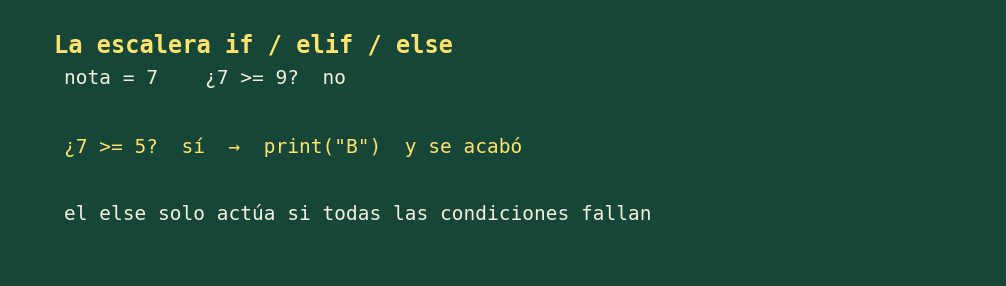

In [10]:
dibujar_pizarra(
    'La escalera if / elif / else',
    [('nota = 7    ¿7 >= 9?  no', TIZA),
    ('¿7 >= 5?  sí  →  print("B")  y se acabó', TIZA_AMARILLA),
    ('el else solo actúa si todas las condiciones fallan', TIZA)],
    ancho=10, alto=2.8,
)

In [11]:
nota = 7
if nota >= 9:
    print("A")
elif nota >= 5:
    print("B")
else:
    print("C")

B


**Paso a paso.** `7` no cumple `>= 9`, así que se evalúa la rama `elif`: `7 >= 5` sí se cumple y se imprime `B`. La `else` ya no se mira. La respuesta es **b) B**.

Por qué fallan las demás:

- **a) A**: evalúa solo la última comparación o invierte el orden.
- **c) C**: cree que 7 cae en el `else`.
- **d) AB**: cree que se ejecutan varias ramas.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=nota%20%3D%207%0Aif%20nota%20%3E%3D%209%3A%0A%20%20%20%20print%28%22A%22%29%0Aelif%20nota%20%3E%3D%205%3A%0A%20%20%20%20print%28%22B%22%29%0Aelse%3A%0A%20%20%20%20print%28%22C%22%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Respuesta b: el `elif` se evalúa solo cuando falla el `if`, y 7 cumple `>= 5`. | 1 |
| Una respuesta incorrecta no resta. | 0 de resta |

#### Errores frecuentes

- Leer las condiciones de abajo arriba o en desorden.
- Pensar que el `elif` y el `else` se ejecutan además del `if`: solo se imprime una rama.

## P6 · Contar libros de dos en dos (WHILE A6 · 1 punto)

### Enunciado exacto

Lucía cuenta los libros del carro de devoluciones de dos en dos y se detiene en cuanto el contador llega a 6 o más. ¿Qué imprime este código?

```python
i = 0
while True:
    i = i + 2
    if i >= 6:
        break
print(i)
```

a) 4    b) 8<br>c) 5    d) 6

### Pizarra

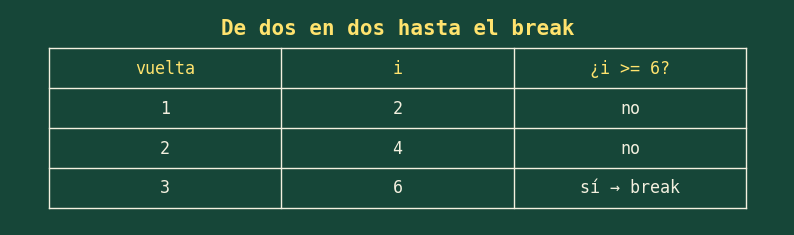

In [12]:
dibujar_tabla_pizarra("De dos en dos hasta el break",
    ["vuelta", "i", "¿i >= 6?"],
    [["1", "2", "no"],
     ["2", "4", "no"],
     ["3", "6", "sí → break"]])

In [13]:
i = 0
while True:
    i = i + 2
    if i >= 6:
        break
print(i)

6


**Paso a paso.** `i` toma 2, 4 y 6. En la tercera vuelta la condición `i >= 6` se cumple y el `break` saca del bucle; el `print` muestra `6`. La respuesta es **d) 6**.

Por qué fallan las demás:

- **a) 4**: sale una vuelta antes.
- **b) 8**: hace una vuelta de más.
- **c) 5**: cree que el bucle para justo antes de superar 6 sin acumular el último paso.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=i%20%3D%200%0Awhile%20True%3A%0A%20%20%20%20i%20%3D%20i%20%2B%202%0A%20%20%20%20if%20i%20%3E%3D%206%3A%0A%20%20%20%20%20%20%20%20break%0Aprint%28i%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Respuesta d: `i` llega a 6 y el `break` sale del `while True`. | 1 |
| Una respuesta incorrecta no resta. | 0 de resta |

#### Errores frecuentes

- Anotar el valor de `i` antes de sumar el `+ 2` de esa vuelta.
- Salir del bucle «por intuición» antes de que la condición `i >= 6` se cumpla de verdad.

## P7 · `append` y longitud (C-V3 A1 = D-V4 A4 · 2 puntos)

### Enunciado exacto

Lucía apunta los libros que presta durante la mañana. ¿Qué imprime este código? (2 ptos)

```python
prestados = ["Momo", "Matilda"]
prestados.append("Dune")
print(len(prestados))
```

Opciones en **C-V3 A1**: a) 2    b) 3    c) 4    d) Dune

La misma pregunta con las opciones reordenadas en **D-V4 A4**: a) Dune    b) 2    c) 4    d) 3

### Pizarra

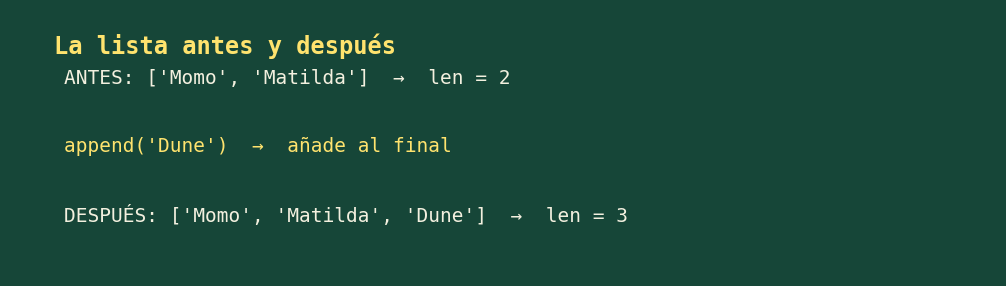

In [14]:
dibujar_pizarra(
    'La lista antes y después',
    [("ANTES: ['Momo', 'Matilda']  →  len = 2", TIZA),
    ("append('Dune')  →  añade al final", TIZA_AMARILLA),
    ("DESPUÉS: ['Momo', 'Matilda', 'Dune']  →  len = 3", TIZA)],
    ancho=10, alto=2.8,
)

In [15]:
prestados = ["Momo", "Matilda"]
prestados.append("Dune")
print(len(prestados))

3


**Paso a paso.** `append` agrega `Dune` al final de la lista. `len` cuenta los elementos después de ese cambio: hay 3, y se imprime `3`. En **C-V3 A1** la respuesta es **b) 3** y en **D-V4 A4** es **d) 3**: las opciones están reordenadas, pero el valor correcto es el mismo.

Por qué fallan las demás:

- **2** (b en D-V4): cuenta los elementos antes de ejecutar `append`.
- **4** (c en ambos): cuenta un elemento de más.
- **Dune** (d en C-V3, a en D-V4): es el elemento añadido, no la longitud.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=prestados%20%3D%20%5B%22Momo%22%2C%20%22Matilda%22%5D%0Aprestados.append%28%22Dune%22%29%0Aprint%28len%28prestados%29%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Respuesta 3 (b en C-V3, d en D-V4): comprende `append` y `len`. | 2 |
| Una respuesta incorrecta no resta. | 0 de resta |

#### Errores frecuentes

- Contar los elementos antes de ejecutar `append`.
- Elegir `Dune`, que es el elemento añadido y no la longitud.
- Memorizar la letra en lugar del valor: la misma respuesta es **b** en C-V3 y **d** en D-V4.

## P8 · Índice de un string (C-V3 A2 · 2 puntos)

### Enunciado exacto

¿Qué imprime este código? (2 ptos)

```python
estante = "NC.N"
print(estante[0])
```

a) N    b) C    c) .    d) NC

### Pizarra

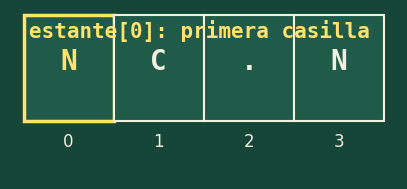

In [16]:
dibujar_estante("NC.N", marcar=[0], titulo="estante[0]: primera casilla")

In [17]:
estante = "NC.N"
print(estante[0])

N


**Paso a paso.** Los índices empiezan en 0. La posición `0` es la primera letra de `NC.N`, que es `N`; por eso se imprime `N`. La respuesta es **a) N**.

Por qué fallan las demás:

- **b) C**: toma la segunda letra, que es el índice 1.
- **c) .**: toma la tercera casilla, el índice 2.
- **d) NC**: responde con más de una letra; un índice devuelve un solo carácter.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=estante%20%3D%20%22NC.N%22%0Aprint%28estante%5B0%5D%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Respuesta a: identifica el índice 0. | 2 |
| Una respuesta incorrecta no resta. | 0 de resta |

#### Errores frecuentes

- Leer `estante[0]` como la segunda casilla.
- Responder con más de una letra: un índice devuelve un solo carácter.

## P9 · `return` frente a `print` (C-V3 A3 = D-V4 A1 · 2 puntos)

### Enunciado exacto

Lucía calcula la multa por retraso de dos maneras distintas (2 euros por día). ¿Cuánto valen a y b después de ejecutar este código? (2 ptos)

```python
def multa_a(dias):
    return dias * 2

def multa_b(dias):
    print(dias * 2)

a = multa_a(5)
b = multa_b(5)
```

a) `a` vale 10 y `b` vale 10    b) `a` vale `None` y `b` vale 10<br>c) `a` vale 10 y `b` vale `None`    d) los dos valen `None`

### Pizarra

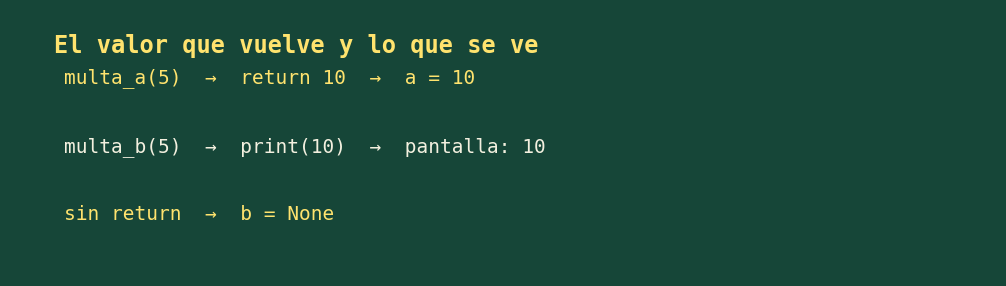

In [18]:
dibujar_pizarra(
    'El valor que vuelve y lo que se ve',
    [('multa_a(5)  →  return 10  →  a = 10', TIZA_AMARILLA),
    ('multa_b(5)  →  print(10)  →  pantalla: 10', TIZA),
    ('sin return  →  b = None', TIZA_AMARILLA)],
    ancho=10, alto=2.8,
)

In [19]:
def multa_a(dias):
    return dias * 2

def multa_b(dias):
    print(dias * 2)

a = multa_a(5)
b = multa_b(5)

10


**Paso a paso.** `multa_a` devuelve `5 * 2`, así que `a` vale `10`. `multa_b` muestra `10` en pantalla, pero no tiene `return`; Python devuelve `None` cuando una función termina sin devolver un valor. Por eso `b` vale `None`. La respuesta es **c) `a` vale 10 y `b` vale `None`**, igual en los dos modelos.

Por qué fallan las demás:

- **a**: confunde `print` con `return` y cree que las dos funciones devuelven 10.
- **b**: invierte qué función devuelve un valor.
- **d**: cree que ninguna de las dos devuelve nada.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=def%20multa_a%28dias%29%3A%0A%20%20%20%20return%20dias%20%2A%202%0A%0Adef%20multa_b%28dias%29%3A%0A%20%20%20%20print%28dias%20%2A%202%29%0A%0Aa%20%3D%20multa_a%285%29%0Ab%20%3D%20multa_b%285%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Respuesta c: distingue el valor devuelto de lo que se imprime. | 2 |
| Una respuesta incorrecta no resta. | 0 de resta |

#### Errores frecuentes

- Tomar el `10` que aparece en pantalla como el valor asignado a `b`.
- Confundir `print` con `return`.

## P10 · Contador y condición (C-V3 A4 = D-V4 A3 · 2 puntos)

### Enunciado exacto

En el club de lectura, cada novela leída da 1 sello en el carné. ¿Qué imprime este código? (2 ptos)

```python
sellos = 0
for libro in ["novela", "revista", "novela"]:
    if libro == "novela":
        sellos = sellos + 1
print(sellos)
```

Opciones en **C-V3 A4**: a) 1    b) 3    c) 0    d) 2

La misma pregunta con las opciones reordenadas en **D-V4 A3**: a) 2    b) 0    c) 3    d) 1

### Pizarra

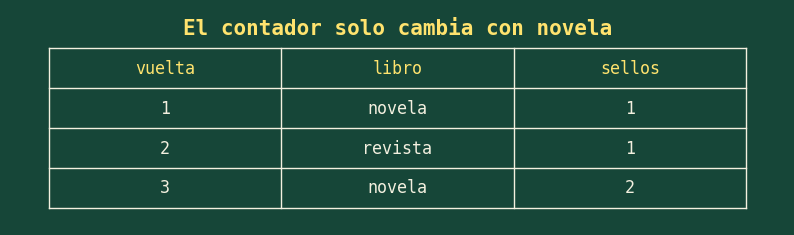

In [20]:
dibujar_tabla_pizarra("El contador solo cambia con novela",
                       ["vuelta", "libro", "sellos"],
                       [["1", "novela", "1"], ["2", "revista", "1"],
                        ["3", "novela", "2"]])

In [21]:
sellos = 0
for libro in ["novela", "revista", "novela"]:
    if libro == "novela":
        sellos = sellos + 1
print(sellos)

2


**Paso a paso.** El bucle visita tres libros. La condición se cumple en la primera y en la tercera vuelta; el contador pasa de 0 a 1 y luego a 2. La revista no lo cambia. Se imprime `2`: es la opción **d) 2** en **C-V3 A4** y la opción **a) 2** en **D-V4 A3**.

Por qué fallan las demás:

- **1** (a en C-V3, d en D-V4): cuenta solo la primera novela.
- **3** (b en C-V3, c en D-V4): suma en las tres vueltas sin comprobar el `if`.
- **0** (c en C-V3, b en D-V4): cree que el contador nunca cambia.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=sellos%20%3D%200%0Afor%20libro%20in%20%5B%22novela%22%2C%20%22revista%22%2C%20%22novela%22%5D%3A%0A%20%20%20%20if%20libro%20%3D%3D%20%22novela%22%3A%0A%20%20%20%20%20%20%20%20sellos%20%3D%20sellos%20%2B%201%0Aprint%28sellos%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Respuesta 2 (d en C-V3, a en D-V4): cuenta solo las novelas. | 2 |
| Una respuesta incorrecta no resta. | 0 de resta |

#### Errores frecuentes

- Sumar en las tres vueltas sin comprobar el `if`.
- Contar vueltas en lugar de contar las veces que se cumple la condición.
- Memorizar la letra en lugar del valor: la misma respuesta es **d** en C-V3 y **a** en D-V4.

## P11 · Diccionario de préstamos (D-V4 A2 · 2 puntos)

### Enunciado exacto

Lucía guarda en un diccionario cuántos libros tiene prestados cada socio. Leo se lleva un libro más y Eva se hace socia y se lleva 3. ¿Qué imprime este código? (2 ptos)

```python
prestamos = {"Ana": 2, "Leo": 1}
prestamos["Leo"] = prestamos["Leo"] + 1
prestamos["Eva"] = 3
print(len(prestamos), prestamos["Leo"])
```

a) 2 2    b) 3 2    c) 3 1    d) 6 2

### Pizarra

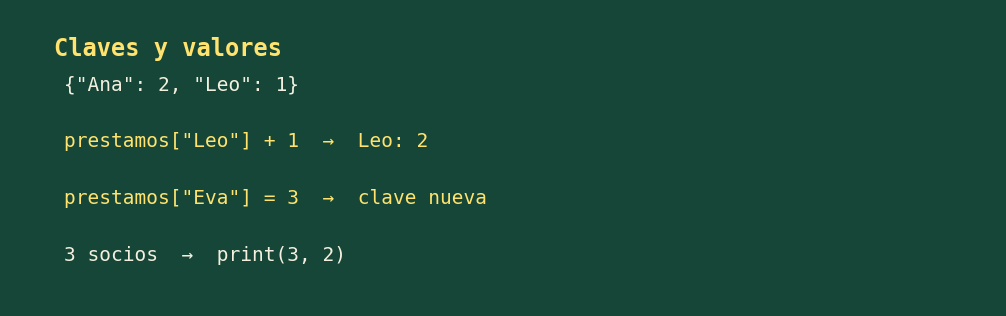

In [22]:
dibujar_pizarra(
    'Claves y valores',
    [('{"Ana": 2, "Leo": 1}', TIZA),
    ('prestamos["Leo"] + 1  →  Leo: 2', TIZA_AMARILLA),
    ('prestamos["Eva"] = 3  →  clave nueva', TIZA_AMARILLA),
    ('3 socios  →  print(3, 2)', TIZA)],
    ancho=10, alto=3.1,
)

In [23]:
prestamos = {"Ana": 2, "Leo": 1}
prestamos["Leo"] = prestamos["Leo"] + 1
prestamos["Eva"] = 3
print(len(prestamos), prestamos["Leo"])

3 2


**Paso a paso.** El diccionario guarda parejas clave → valor. `prestamos['Leo'] + 1` deja a Leo con 2. `prestamos['Eva'] = 3` crea una clave nueva: el diccionario pasa a tener 3 socios. El `print` muestra `3 2`: **b)**.

Por qué fallan las demás:

- **a) 2 2**: olvida que `Eva` es una clave nueva y se queda en 2 socios.
- **c) 3 1**: responde el valor de Leo antes de sumar.
- **d) 6 2**: suma los libros de todos en lugar de contar las claves.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=prestamos%20%3D%20%7B%22Ana%22%3A%202%2C%20%22Leo%22%3A%201%7D%0Aprestamos%5B%22Leo%22%5D%20%3D%20prestamos%5B%22Leo%22%5D%20%2B%201%0Aprestamos%5B%22Eva%22%5D%20%3D%203%0Aprint%28len%28prestamos%29%2C%20prestamos%5B%22Leo%22%5D%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Respuesta b: entiende las claves y los valores del diccionario. | 2 |
| Una respuesta incorrecta no resta. | 0 de resta |

#### Errores frecuentes

- Olvidar que `Eva` es una clave nueva y quedarse en 2 socios (opción a).
- Responder el valor de Leo antes de sumar: `3 1` (opción c).
- Sumar los libros de todos en lugar de contar las claves (opción d).
- Ojo al orden del `print`: aquí va primero el `len`; en la P2 (WHILE A2) iba primero el valor.

# Resumen final

| Cuaderno | En el examen | Respuesta oficial | Puntos |
|---|---|---|---:|
| P1 | WHILE A1 | c) 2 | 1 |
| P2 | WHILE A2 | b) 3 3 | 1 |
| P3 | WHILE A3 | a) 30 4 | 1 |
| P4 | WHILE A4 | c) 5 0 | 1 |
| P5 | WHILE A5 | b) B | 1 |
| P6 | WHILE A6 | d) 6 | 1 |
| P7 | C-V3 A1 = D-V4 A4 | 3 (b en C-V3 · d en D-V4) | 2 |
| P8 | C-V3 A2 | a) N | 2 |
| P9 | C-V3 A3 = D-V4 A1 | c) `a = 10`, `b = None` | 2 |
| P10 | C-V3 A4 = D-V4 A3 | 2 (d en C-V3 · a en D-V4) | 2 |
| P11 | D-V4 A2 | b) 3 2 | 2 |
| **Total** | **11 preguntas** | **6 puntos del WHILE + 10 de C-V3/D-V4** | **16** |

## Dudas frecuentes

**¿Por qué `b` vale `None` en la P9?**  
`multa_b` imprime el resultado, pero no tiene `return`; por eso no entrega un valor y la asignación recibe `None`.

**¿Por qué la P2 y la P11 se parecen tanto?**  
Trabajan la misma idea (actualizar una clave y crear otra nueva), pero son preguntas distintas: cambian los socios y el orden del `print`. En la P2 se imprime `prestamos["Luna"], len(prestamos)` → `3 3`; en la P11, `len(prestamos), prestamos["Leo"]` → `3 2`.

**¿Cómo puede la misma respuesta ser b en un examen y d en otro (P7, P10)?**  
Los dos modelos comparten el enunciado y el código, pero las opciones están ordenadas de forma distinta. Fíjate siempre en el valor, no en la letra.

**¿Por qué `get("agua", 0)` no da `KeyError` en la P4?**  
`get` devuelve el valor por defecto cuando la clave no está. El `KeyError` solo aparece con el acceso directo `inventario["agua"]`.

**¿Resta una respuesta incorrecta?**  
No: cada acierto suma 1 punto en el WHILE y 2 en C-V3 y D-V4, y un fallo no quita puntos.